In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# Load results
# ------------------------------------------------------------

CSV_FILE = "./qdl_fso_quantum_example_results.csv"

df = pd.read_csv(CSV_FILE)

# Make sure rows are ordered in time
df = df.sort_values("time_s").reset_index(drop=True)

# To not plot the fidelity line for blockage, as it does not make sense to compute the fidelity on something that is never RXed
df.loc[df["atm_condition"] == "blockage", "tx_fidelity"] = np.nan


display(df.head(5))
display(df.tail(5))
print(f"Number of events: {len(df)}")
print(df["event"].value_counts())
# print(df[df["atm_condition"] =="blockage"].event.value_counts())

,time_s,qubit_id,node,event,fidelity,transmissivity,atm_condition,x,y,z,distance,tx_fidelity
0,0.000000e+00,4,0,TX,NaN,0.000000,clear_air,0.0,0.000000,20.0,250.683565,0.986192
1,8.360000e-07,4,1,LOST,NaN,NaN,clear_air,250.0,0.000000,1.5,NaN,NaN
2,1.000000e-02,6,0,TX,NaN,0.919207,clear_air,0.0,0.000000,20.0,250.683565,0.986192
3,1.000084e-02,6,1,RX,1.0,NaN,clear_air,250.0,0.015708,1.5,NaN,NaN
4,2.000000e-02,8,0,TX,NaN,0.924992,clear_air,0.0,0.000000,20.0,250.683565,0.986192


,time_s,qubit_id,node,event,fidelity,transmissivity,atm_condition,x,y,z,distance,tx_fidelity
199997,999.980001,200000,1,LOST,NaN,NaN,blockage,249.999996,-0.047123,1.5,NaN,NaN
199998,999.990000,200002,0,TX,NaN,0.0,blockage,0.000000,0.000000,20.0,250.683565,NaN
199999,999.990001,200002,1,LOST,NaN,NaN,blockage,249.999998,-0.031416,1.5,NaN,NaN
200000,1000.000000,200004,0,TX,NaN,0.0,blockage,0.000000,0.000000,20.0,250.683565,NaN
200001,1000.000001,200004,1,LOST,NaN,NaN,blockage,250.000000,-0.015708,1.5,NaN,NaN


Number of events: 200002
event
TX      100001
RX       69457
LOST     30544
Name: count, dtype: int64


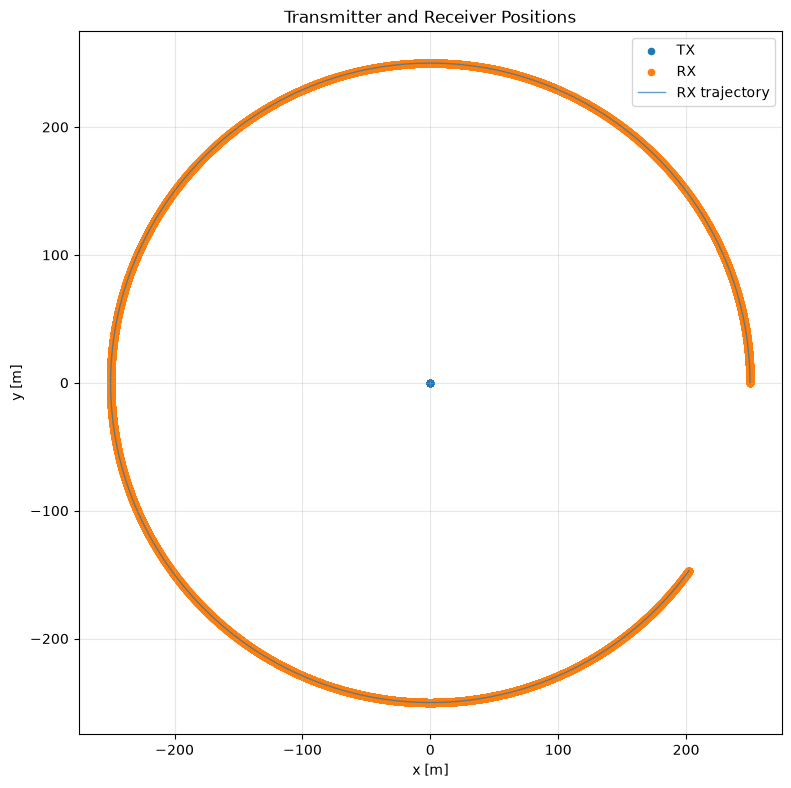

In [2]:
# ------------------------------------------------------------
# TX and RX positions
# ------------------------------------------------------------

tx = df[df["event"] == "TX"].copy()
rx = df[df["event"] == "RX"].copy()

fig, ax = plt.subplots(figsize=(8, 8))

# TX positions
ax.scatter(
    tx["x"],
    tx["y"],
    s=20,
    label="TX",
)

# RX positions
ax.scatter(
    rx["x"],
    rx["y"],
    s=20,
    label="RX",
)

# Connect RX positions to show the trajectory
if not rx.empty:
    ax.plot(
        rx["x"],
        rx["y"],
        linewidth=1,
        alpha=0.7,
        label="RX trajectory",
    )

ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_title("Transmitter and Receiver Positions")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

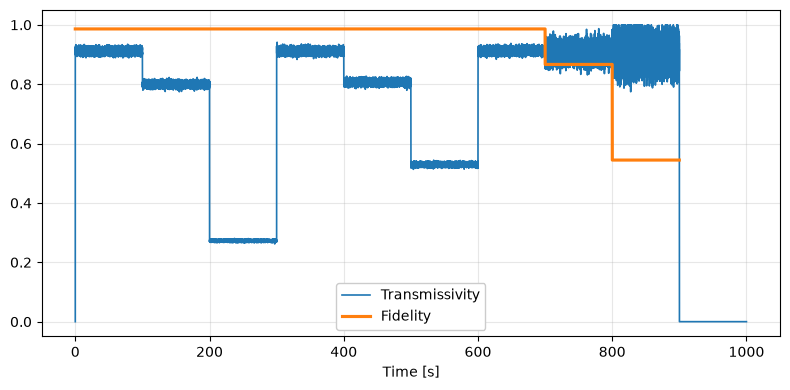

In [3]:
# ------------------------------------------------------------
# Transmissivity and fidelity comparison
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    tx["time_s"],
    tx["transmissivity"],
    linewidth=1.2,
    label="Transmissivity",
)

ax.plot(
    tx["time_s"],
    tx["tx_fidelity"],
    linewidth=2.25,
    label="Fidelity",
)

ax.set_xlabel("Time [s]")

ax.grid(True, alpha=0.3)

ax.set_ylim(-0.05, 1.05)

ax.legend(
    framealpha=1
)

plt.tight_layout()
plt.savefig("qdl-fso-quantum-example_transmissivity_fidelity.pdf")
plt.show()

(2789, 12)


/tmp/ipykernel_111440/528727499.py:46: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


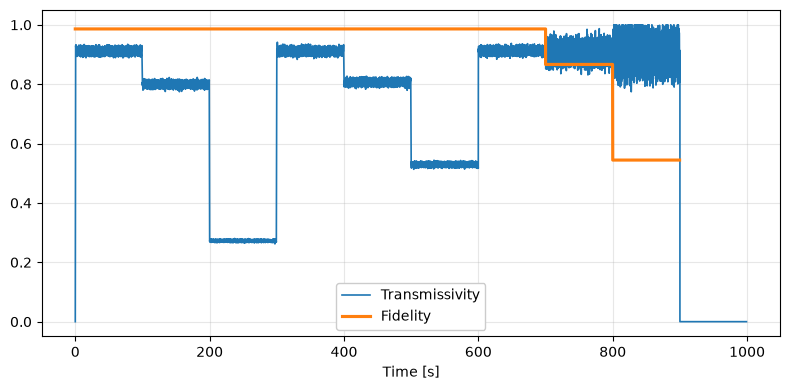

In [4]:
def minmax_decimate(df, cols, n_bins=750):
    bins = np.array_split(np.arange(len(df)), n_bins)
    keep = []
    for b in bins:
        for c in cols:
            keep += [b[df[c].values[b].argmin()], b[df[c].values[b].argmax()]]
    return df.iloc[sorted(set(keep))]

tx_small = minmax_decimate(tx, ["transmissivity", "tx_fidelity"], n_bins=1000)

print(tx_small.shape)

# Save the reduced csv file, to be used in the tickz image in the paper
tx_small[["time_s", "transmissivity", "tx_fidelity"]].to_csv(
    "qdl_fso_quantum_example_results_small.csv", index=False, float_format="%.5g"
)

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    tx_small["time_s"],
    tx_small["transmissivity"],
    linewidth=1.2,
    label="Transmissivity",
)

ax.plot(
    tx_small["time_s"],
    tx_small["tx_fidelity"],
    linewidth=2.25,
    label="Fidelity",
)

ax.set_xlabel("Time [s]")

ax.grid(True, alpha=0.3)

ax.set_ylim(-0.05, 1.05)

ax.legend(
    framealpha=1
)

plt.tight_layout()

fig.show()

In [5]:
summary = (
    df.groupby("atm_condition")
    .agg(
        mean_transmissivity=("transmissivity","mean"),
        std_transmissivity=("transmissivity","std"),
        mean_fidelity=("fidelity", "mean"),
        std_fidelity=("fidelity", "std"),
        mean_tx_fidelity=("tx_fidelity", "mean"),
        std_tx_fidelity=("tx_fidelity", "std"),
        lost=("event", lambda x: (x == "LOST").sum()),
        rx=("event", lambda x: (x == "RX").sum()),
    )
)

total = summary["lost"] + summary["rx"]

summary["lost_percentage"] = 100 * summary["lost"] / total
summary["rx_percentage"] = 100 * summary["rx"] / total

summary = summary[
    [
        "mean_transmissivity",
        "std_transmissivity",
        "mean_fidelity",
        "std_fidelity",
        "mean_tx_fidelity",
        "std_tx_fidelity",
        "lost_percentage",
        "rx_percentage",
    ]
].round(2)

display(summary)

,mean_transmissivity,std_transmissivity,mean_fidelity,std_fidelity,mean_tx_fidelity,std_tx_fidelity,lost_percentage,rx_percentage
atm_condition,,,,,,,,
blockage,0.00,0.01,1.00,NaN,NaN,NaN,99.99,0.01
clear_air,0.91,0.01,0.99,0.12,0.99,0.0,8.90,91.10
fog,0.27,0.00,0.99,0.12,0.99,0.0,72.69,27.31
haze,0.80,0.01,0.99,0.12,0.99,0.0,20.36,79.64
heavy_rain,0.53,0.00,0.98,0.12,0.99,0.0,46.91,53.09
light_rain,0.81,0.01,0.98,0.12,0.99,0.0,19.48,80.52
severe_turbulence,0.90,0.04,0.55,0.50,0.54,0.0,9.43,90.57
strong_turbulence,0.90,0.02,0.87,0.34,0.87,0.0,9.88,90.12
